Années chargées : [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2024, 2025, 2026] | lignes : 2239
Lignes non numériques supprimées (en-têtes répétés) : 11
Lignes écartées (taux > 30 %) : 21 sur 2228
Secteurs présents les 10 années : 9 sur 17
       nb_activites  taux_moyen  taux_median  taux_max
annee                                                 
2016            284        3.18         2.70     10.00
2017            216        2.90         2.50     10.20
2018            214        2.92         2.50     23.00
2019            214        2.86         2.45      9.90
2020            213        2.92         2.50     10.10
2021            213        2.87         2.40      9.70
2022            213        2.92         2.41     10.04
2024            213        2.80         2.32      9.40
2025            213        2.81         2.33     10.74
2026            214        2.74         2.33      8.73


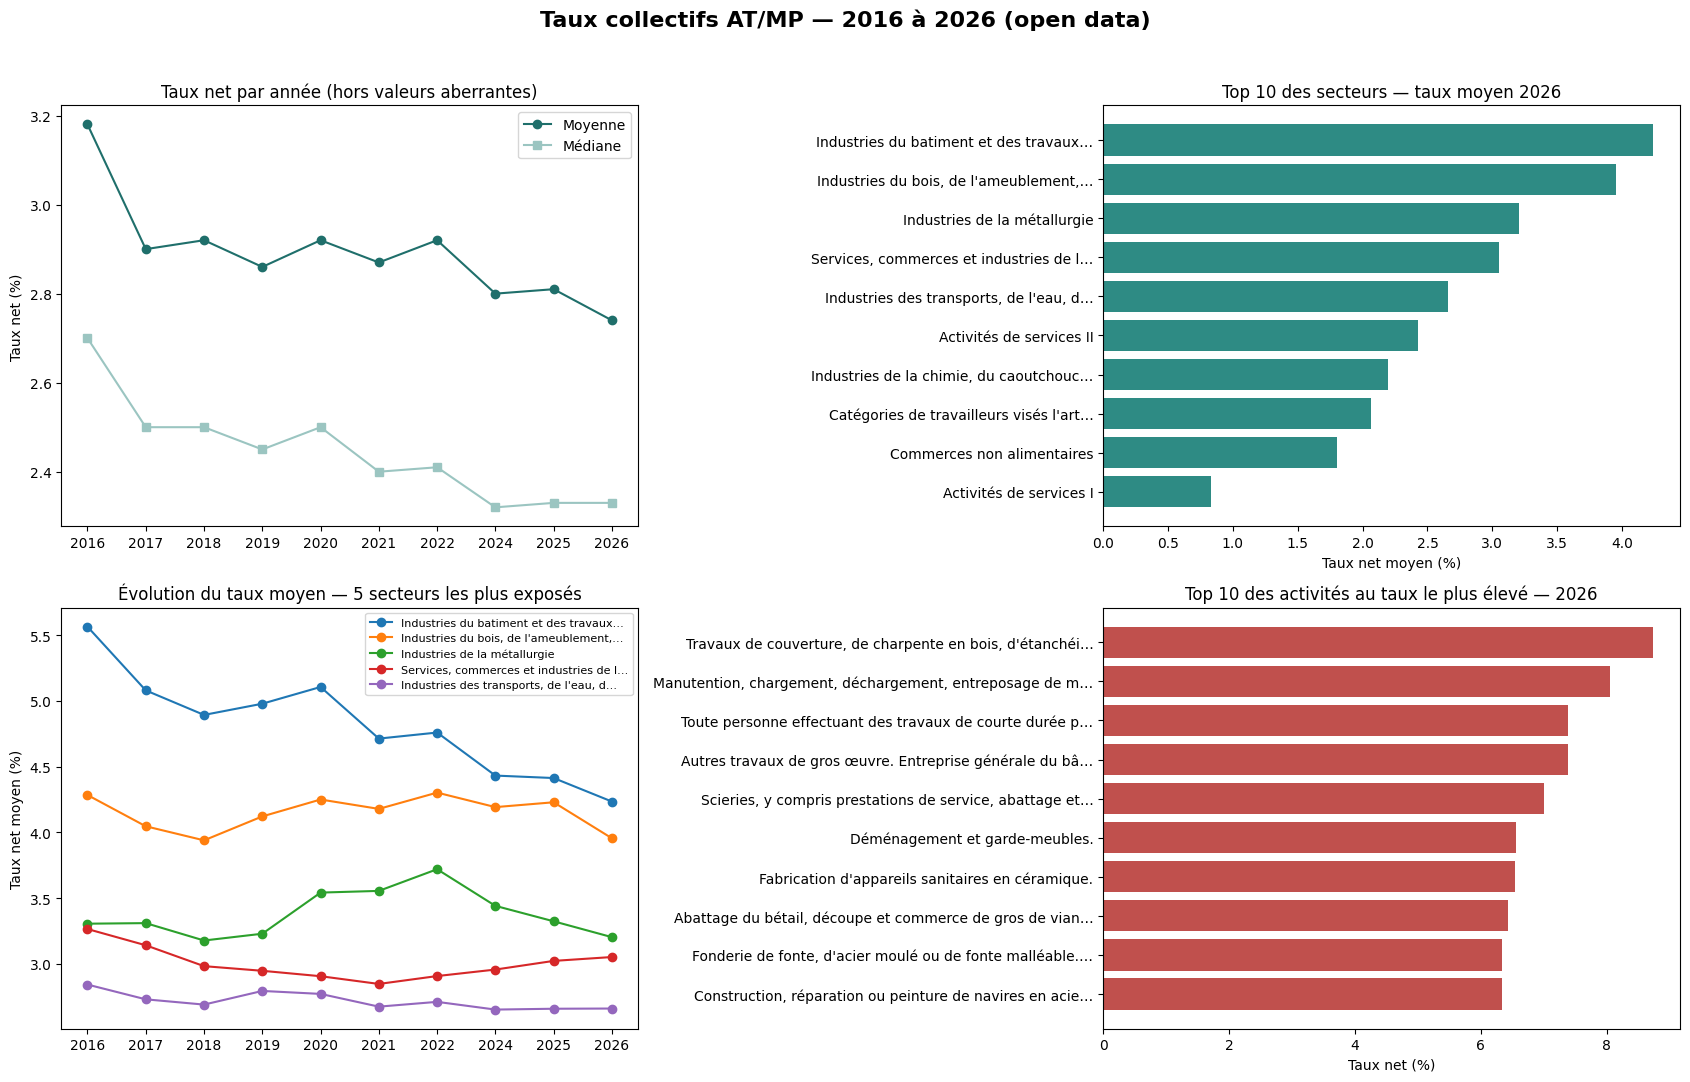

Fichier créé : atmp_nettoye_2016_2026.csv


In [ ]:
#  10 années de données (2016 à 2026) =====
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt

URL_BASE = "https://raw.githubusercontent.com/betagouv/taux-collectifs-cotisation-atmp/master/"
ANNEES_CSV = [2016, 2017, 2018]
ANNEES_JSON = [2019, 2020, 2021, 2022, 2024, 2025, 2026]     # pas de fichier 2023 dans le dépôt
COLONNES = {"Nature du risque": "activite", "Code risque": "code",
            "Taux net": "taux_net", "Catégorie": "secteur"}

# 1) Charger : CSV pour 2016-2018, JSON pour 2019-2026
tableaux = []
for a in ANNEES_CSV:
    t = pd.read_csv(f"{URL_BASE}taux-{a}.csv", dtype=str)
    t["annee"] = a
    tableaux.append(t)
for a in ANNEES_JSON:
    t = pd.read_json(f"{URL_BASE}taux-{a}.json", dtype=str)
    t["annee"] = a
    tableaux.append(t)

# On ne garde que les 4 colonnes utiles : les fichiers n'ont pas tous les mêmes colonnes
brut = pd.concat([t[list(COLONNES) + ["annee"]] for t in tableaux], ignore_index=True)
brut = brut.rename(columns=COLONNES)
ANNEES = [int(a) for a in sorted(brut["annee"].unique())]
print("Années chargées :", ANNEES, "| lignes :", len(brut))

# 2) Nettoyer : « 6,34 % » -> 6.34 ; certaines lignes sont des en-têtes répétés (« TAUX NET (en %) »)
brut["taux_net"] = (brut["taux_net"].str.replace("%", "", regex=False)
                    .str.replace(r"\s+", "", regex=True).str.replace(",", ".", regex=False))
brut["taux_net"] = pd.to_numeric(brut["taux_net"], errors="coerce")
print("Lignes non numériques supprimées (en-têtes répétés) :", int(brut["taux_net"].isna().sum()))
df = brut.dropna(subset=["taux_net"]).copy()

for col in ["activite", "secteur"]:
    df[col] = df[col].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["secteur"] = df["secteur"].str.upper()

def sans_accents(texte):
    return "".join(c for c in unicodedata.normalize("NFD", texte) if unicodedata.category(c) != "Mn")

def court(texte, n):
    return texte if len(texte) <= n else texte[:n].rstrip() + "…"

df["cle_secteur"] = df["secteur"].map(sans_accents)
dernier_nom = df.sort_values("annee").groupby("cle_secteur")["secteur"].last()
df["secteur_court"] = (df["cle_secteur"].map(dernier_nom).str.capitalize()
                       .str.replace(r"\b(ii|i)\b", lambda m: m.group(1).upper(), regex=True)
                       .map(lambda t: court(t, 38)))

# 3) Valeurs aberrantes + secteurs présents toutes les années
SEUIL = 30
df_ok = df[df["taux_net"] <= SEUIL].copy()
print(f"Lignes écartées (taux > {SEUIL} %) : {len(df) - len(df_ok)} sur {len(df)}")
presence = df.groupby("cle_secteur")["annee"].nunique()
secteurs_stables = presence[presence == len(ANNEES)].index
print(f"Secteurs présents les {len(ANNEES)} années : {len(secteurs_stables)} sur {len(presence)}")

# 4) KPI par année
kpi = df_ok.groupby("annee")["taux_net"].agg(nb_activites="count", taux_moyen="mean",
                                             taux_median="median", taux_max="max").round(2)
print(kpi.to_string())

# 5) Tableau de bord : évolution sur 10 ans
derniere = max(ANNEES)
x_annees = [str(a) for a in kpi.index]            # axe « catégories » : évite d'inventer une année 2023
fig, axes = plt.subplots(2, 2, figsize=(17, 11))
fig.suptitle(f"Taux collectifs AT/MP — {ANNEES[0]} à {derniere} (open data)", fontsize=16, fontweight="bold")

ax = axes[0, 0]
ax.plot(x_annees, kpi["taux_moyen"], marker="o", color="#1F6F6B", label="Moyenne")
ax.plot(x_annees, kpi["taux_median"], marker="s", color="#9BC5C1", label="Médiane")
ax.set_title("Taux net par année (hors valeurs aberrantes)"); ax.set_ylabel("Taux net (%)"); ax.legend()

ax = axes[0, 1]
top_secteurs = df_ok[df_ok.annee == derniere].groupby("secteur_court")["taux_net"].mean().sort_values().tail(10)
ax.barh(top_secteurs.index, top_secteurs.values, color="#2E8B84")
ax.set_title(f"Top 10 des secteurs — taux moyen {derniere}"); ax.set_xlabel("Taux net moyen (%)")

ax = axes[1, 0]
stables = df_ok[df_ok.cle_secteur.isin(secteurs_stables)]
pivot = stables.pivot_table(index="annee", columns="secteur_court", values="taux_net", aggfunc="mean")
for s in pivot.loc[derniere].sort_values(ascending=False).head(5).index:
    ax.plot([str(a) for a in pivot.index], pivot[s], marker="o", label=s)
ax.set_title("Évolution du taux moyen — 5 secteurs les plus exposés"); ax.set_ylabel("Taux net moyen (%)")
ax.legend(fontsize=8)

ax = axes[1, 1]
top_act = df_ok[df_ok.annee == derniere].nlargest(10, "taux_net").sort_values("taux_net")
ax.barh(top_act["activite"].map(lambda t: court(t, 55)), top_act["taux_net"], color="#C0504D")
ax.set_title(f"Top 10 des activités au taux le plus élevé — {derniere}"); ax.set_xlabel("Taux net (%)")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 6) Export pour Power BI / Looker Studio
df_ok.to_csv("atmp_nettoye_2016_2026.csv", index=False)
print("Fichier créé : atmp_nettoye_2016_2026.csv")

In [ ]:
# filtre interactif =====
from ipywidgets import interact, Dropdown, SelectionSlider

secteurs = sorted(df_ok[df_ok.cle_secteur.isin(secteurs_stables)]["secteur_court"].unique())

def explorer(secteur, annee):
    d = df_ok[df_ok.secteur_court == secteur]
    evol = d.groupby("annee")["taux_net"].agg(["mean", "median"])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
    x = [str(a) for a in evol.index]
    ax1.plot(x, evol["mean"], marker="o", color="#1F6F6B", label="Moyenne")
    ax1.plot(x, evol["median"], marker="s", color="#9BC5C1", label="Médiane")
    ax1.axvline(str(annee), color="grey", linestyle="--", alpha=0.6)      # repère de l'année choisie
    ax1.set_title(f"Évolution du taux net\n{secteur}")
    ax1.set_ylabel("Taux net (%)"); ax1.legend()

    top = d[d.annee == annee].nlargest(5, "taux_net").sort_values("taux_net")
    ax2.barh(top["activite"].map(lambda t: court(t, 50)), top["taux_net"], color="#C0504D")
    ax2.set_title(f"5 activités au taux le plus élevé en {annee}")
    ax2.set_xlabel("Taux net (%)")
    plt.tight_layout()
    plt.show()

interact(explorer,
         secteur=Dropdown(options=secteurs, description="Secteur"),
         annee=SelectionSlider(options=[int(a) for a in ANNEES], value=int(derniere), description="Année"))

interactive(children=(Dropdown(description='Secteur', options=('Activités de services I', 'Activités de servic…

<function __main__.explorer(secteur, annee)>

In [ ]:
from google.colab import files

fig.savefig("dashboard_atmp_10ans.png", dpi=150, bbox_inches="tight")

files.download("dashboard_atmp_10ans.png")
files.download("atmp_nettoye_2016_2026.csv")